<a href="https://colab.research.google.com/github/Nahi05/ISSD-PH/blob/main/TP2_PH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adquisición y metadatos

In [1]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 28.8 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 36.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pymupdf]


In [2]:
import requests
import pymupdf
import os

In [3]:
url= "https://arxiv.org/pdf/2610.35766"
nom_archivo= "articulo.pdf"

resp= requests.get(url)

with open(nom_archivo, "wb") as f:
  f.write(resp.content)

print("codigo de estado HTTP:", resp.status_code)

codigo de estado HTTP: 200


# Metadatos

In [4]:
doc= pymupdf.open(nom_archivo)
metadata_arch= doc.metadata

print("cantidad de paginas:", doc.page_count)
print("titulo:", metadata_arch["title"])
print("autor:", metadata_arch["author"])
print("software de creacion:", metadata_arch["creator"])

cantidad de paginas: 17
titulo: Improving Signals, Declining Encoder: A Known-Answer Test of Label-Free Monitoring in Self-Supervised Learning
autor: Nilotpal Kakati
software de creacion: arXiv GenPDF (tex2pdf:07e334b)


# Analisis estructural del texto

## Extracción cruda

In [14]:
texto = "".join(p.get_text("text") for p in doc)

print(texto.replace("\n", "\\n\n"))

Improving Signals, Declining Encoder:\n
A Known-Answer\n
Test of Label-Free Monitoring in Self-Supervised Learning\n
Nilotpal Kakati\n
nilotpal.kakati09@gmail.com\n
Weizmann Institute of Science, Rehovot, Israel\n
Abstract\n
Self-supervised training is monitored without labels, through the loss and statistics of the\n
learned features. We report a case where we know the encoders lost part of what they had\n
learned, so we can check whether these signals noticed. We trained LeJEPA encoders on\n
synthetic images with known generating factors. In nine of ten seeds, the readability of\n
those factors fell abruptly and stayed down, nearly always along the same direction in factor\n
space. Meanwhile the loss kept falling, and most of the eleven label-free signals we tracked\n
kept improving and rated the declining runs better than runs that did not decline. Standard\n
change-point detection rarely flagged the decline near its onset, and selecting checkpoints\n
by these signals mostly chose o

## Análisis de separadores
- **Párrafos:** no tienen una marca propia. Cada línea del texto termina en \n, y un párrafo nuevo empieza en la línea siguiente, sin línea en blanco. Solo se nota porque la última línea del párrafo anterior es más corta.
- **Secciones:** el título va en su propia línea, y el número de la sección queda en una línea aparte, justo antes del título.
- **Capítulos:** no hay. El documento es un paper y su nivel más alto son las secciones.

## Identificación de caracteres
En general, el único separador del archivo es \n, y la estructura (párrafos, títulos, secciones) hay que reconocerla por el contenido de cada línea y no por una marca en el texto.


# Extracción de datos tabulares

In [6]:
!pip install pdfplumber

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 18.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 32.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 37.0 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [7]:
import pdfplumber
import pandas as pd

In [8]:
pdf_plumber= pdfplumber.open(nom_archivo)

In [15]:
pag_tabla= pdf_plumber.pages[12]

texto= pag_tabla.extract_text()
lineas= texto.split("\n")

inicio= 0
final= 0
for i, linea in enumerate(lineas):
  if linea.startswith("Condition"):
    inicio= i
  if linea.startswith("MAE,"):
    final= i

filas_texto= lineas[inicio + 1 : final + 1]

filas= []
for linea in filas_texto:
  partes= linea.split(" ")
  condicion= " ".join(partes[:-5])
  filas.append([condicion] + partes[-5:])

columnas= ["Condition", "Width", "Epochus", "Runs", "Declines", "Drop range"]
df= pd.DataFrame(filas, columns=columnas)

for col in ["Width", "Epochus", "Runs", "Declines"]:
  df[col]= pd.to_numeric(df[col], errors="coerce")

print(df.shape)
df


(10, 6)


,Condition,Width,Epochus,Runs,Declines,Drop range
0,"µ=0, ρ=0.9",384.0,1000,6,0,0.00023–0.012
1,"µ=0, no weight decay",384.0,300,3,1,0–0.29
2,"µ=0, constant LR",384.0,300,3,2,0.027–0.27
3,"µ=0, SIGReg weight 0.05",384.0,300,10,3,0–0.27
4,"µ=0.9, cosine LR",384.0,1000,3,3,0.21–0.55
5,"µ=0.9, constant LR",384.0,1000,3,3,0.28–0.31
6,"µ=0.97, cosine LR",384.0,1000,3,0,0.0019–0.036
7,"µ=0.97, ρ=0.9",384.0,300,3,0,0.0023–0.023
8,"ViT-Tiny, µ=0",2048.0,300,2,1,0–0.094
9,"MAE, µ=0",NaN,300,10,0,0


## Análisis de frecuencias (NLP básico)

In [10]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

### Tokenización

In [11]:
texto= doc[6].get_text()
tokens= word_tokenize(texto.lower(), language='english')

print("cantidad de tokens:", len(tokens))

cantidad de tokens: 795


### Limpieza

In [12]:
lista_stop_words= set(stopwords.words('english'))
filtrados= [word for word in tokens if word.isalpha() and word not in lista_stop_words]

print(f"limpieza: {len(filtrados)}")
filtrados

limpieza: 374


['known',
 'generating',
 'factors',
 'used',
 'test',
 'unsupervised',
 'models',
 'learn',
 'locatello',
 'et',
 'al',
 'trained',
 'thousands',
 'models',
 'factor',
 'datasets',
 'found',
 'models',
 'seemingly',
 'could',
 'identified',
 'without',
 'supervision',
 'result',
 'counterpart',
 'lejepa',
 'klindt',
 'et',
 'al',
 'prove',
 'objective',
 'optimum',
 'recovers',
 'gaussian',
 'generating',
 'factors',
 'two',
 'views',
 'factors',
 'related',
 'identical',
 'shared',
 'views',
 'identical',
 'objective',
 'longer',
 'favours',
 'recovering',
 'factors',
 'theorem',
 'concerns',
 'optimum',
 'rather',
 'path',
 'training',
 'takes',
 'says',
 'nothing',
 'either',
 'way',
 'declines',
 'refresh',
 'runs',
 'main',
 'guarantee',
 'original',
 'lejepa',
 'paper',
 'balestriero',
 'lecun',
 'isotropic',
 'gaussian',
 'embeddings',
 'serve',
 'downstream',
 'probes',
 'best',
 'concerns',
 'embeddings',
 'distributed',
 'factors',
 'keep',
 'simon',
 'et',
 'al',
 'find',
 

### Visualización

<Axes: title={'center': '15 palabras más frecuentes en el articulo'}>

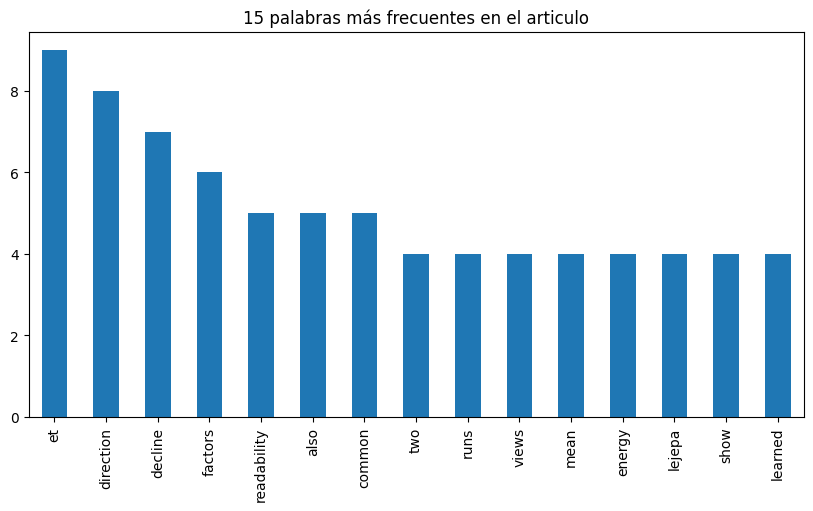

In [13]:
frecuencias= pd.Series(filtrados).value_counts().head(15)
frecuencias.plot(kind="bar", figsize=(10,5), title= "15 palabras más frecuentes en el articulo")

#### Análisis del gráfico
Después de eliminar las stop words y la puntuación, las palabras más frecuentes que aportan contenido son direction, decline, factors, readability y common, que reflejan el tema de la página: la pérdida de legibilidad de los factores en el modelo.

Sin embargo, aparecieron tokens que también considero stop words:

- et (la más frecuente, con 9 apariciones): viene de las citas bibliográficas (*Locatello et al.*). No tiene peso semántico, solo indica autoría. Su compañera al aparece menos veces (3), probablemente porque el tokenizador deja el punto pegado (al.) y el filtro isalpha() la descarta en esos casos.
- also, one y two: son un conector y dos cantidades que funcionan como palabras funcionales, y la lista estándar de NLTK no las incluye.
- show: es un verbo genérico de redacción académica ("the results show...") que no dice nada sobre el tema.

Esto ocurre porque la lista de stop words de NLTK es general y no está pensada para textos académicos. Conviene ampliarla con estas palabras para que el gráfico muestre mejor de qué trata la página.